# Deepfake Audio Feature Extraction: MFCC / LFCC / CQCC

Pulls **5 clips each** of:
- English **real** (bonafide) — ASVspoof 2019 (LA)
- English **fake** (spoofed/TTS-VC) — ASVspoof 2019 (LA)
- Gujarati **fake** (TTS) — IndicSynth
- Gujarati **real** (bonafide) — Google FLEURS (`gu_in`)

...then extracts MFCC, LFCC and CQCC features for each clip and visualizes them.

### Data sources (all freely downloadable, no registration/email needed)
| Category | Dataset | Access |
|---|---|---|
| English real & fake | `Bisher/ASVspoof_2019_LA` (HF) — auto-converted Parquet mirror of ASVspoof 2019 LA | public, plain parquet, no loading script |
| Gujarati fake | `vdivyasharma/IndicSynth` (HF), config `Gujarati` | public, `datasets` library |
| Gujarati real | `google/fleurs`, config `gu_in` (HF) | public, CC-BY, `datasets` library |

Note: the official IIT-Mandi/AIR corpus (used in the table you shared) is **not** publicly
mirrored anywhere — it's only available by emailing `speechiitmandi@gmail.com`. FLEURS
Gujarati is used here instead as a freely-downloadable stand-in for real/bonafide Gujarati
speech. If you do get access to AIR later, swap in your own file list using the
`select_random_files()` helper further down.

### ⚠️ Fixed in this version
Two separate problems from earlier runs are fixed here:
1. **Full-dataset downloads.** Every source below is loaded with **`streaming=True`**, so
   only the handful of shards actually touched while scanning for 5 matching clips get
   fetched — never the whole dataset (no more 26GB downloads to interrupt).
2. **`LanceaKing/asvspoof2019` is now dead.** Hugging Face's `datasets` library removed
   support for custom loading scripts in v4.0, and that mirror relied on one — it now fails
   unconditionally with "Dataset scripts are no longer supported." This version switches to
   `SpeechAntiSpoofingBenchmarks/ASVspoof2019_LA`, a plain **parquet** mirror of the same
   ASVspoof 2019 LA eval set (71.2k clips, `label` column: 0=bonafide, 1=spoof) that needs no
   loading script and works fine with current `datasets` versions.
3. Each category is wrapped in its own `try/except`, so if one source fails, the rest still
   load and you can plot whatever succeeded (see Section 9).

## 1. Install & import dependencies

In [ ]:
!pip install torchaudio librosa scipy soundfile huggingface_hub datasets kagglehub --upgrade -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 774.9/774.9 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 15.1 MB/s eta 0:00:00


In [ ]:
import os
import glob
import random
import warnings

import torch
import torchaudio
import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fftpack import dct

warnings.filterwarnings("ignore")

random.seed(42)
np.random.seed(42)

TARGET_SR = 16000
N_CLIPS_PER_CATEGORY = 5

## 2. Load English real/fake — ASVspoof 2019 (LA) via Hugging Face

In [ ]:
from datasets import load_dataset

asvspoof_stream = None
try:
    # Parquet-format mirror (auto-converted, no loading script) -> streams lazily, no full download
    asvspoof_stream = load_dataset("Bisher/ASVspoof_2019_LA", split="train", streaming=True)
    print("ASVspoof2019 LA stream ready (Parquet mirror, streaming=True -> nothing downloaded yet).")
except Exception as e:
    asvspoof_stream = None
    print("Could not open ASVspoof2019 stream:", e)


README.md:   0%|          | 0.00/784 [00:00<?, ?B/s]

ASVspoof2019 LA stream ready (Parquet mirror, streaming=True -> nothing downloaded yet).


**Fallback (only run if the cell above failed):** Kaggle mirror of ASVspoof 2019.
Requires a free Kaggle account — upload your `kaggle.json` API token to Colab first
(`Kaggle → Account → Create New Token`), or use `kagglehub.login()`.

In [ ]:
if asvspoof_stream is None:
    import kagglehub
    kaggle_path = kagglehub.dataset_download("awsaf49/asvpoof-2019-dataset")
    print("Downloaded Kaggle ASVspoof2019 mirror to:", kaggle_path)
    # Note: this Kaggle mirror only ships as a full download (no per-file streaming),
    # so only use this fallback if the parquet-mirror cell above failed.
    print(os.listdir(kaggle_path))


## 3. Load Gujarati fake — IndicSynth (Hugging Face)

In [ ]:
INDICSYNTH_LANG = "Gujarati"
indicsynth_stream = None
try:
    # IndicSynth is loaded per-language via the `name=` config, same pattern as FLEURS below
    indicsynth_stream = load_dataset(
        "vdivyasharma/IndicSynth", name=INDICSYNTH_LANG, split="train", streaming=True
    )
    print(f"IndicSynth {INDICSYNTH_LANG} stream ready (streaming=True -> nothing downloaded yet).")
except Exception as e:
    indicsynth_stream = None
    print("Could not open IndicSynth stream:", e)


README.md:   0%|          | 0.00/13.9k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/54 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/72 [00:00<?, ?it/s]

IndicSynth Gujarati stream ready (streaming=True -> nothing downloaded yet).


## 4. Load Gujarati real — Google FLEURS (`gu_in`)

In [ ]:
fleurs_stream = None
try:
    fleurs_stream = load_dataset("google/fleurs", "gu_in", split="test", streaming=True)
    print("FLEURS Gujarati stream ready (streaming=True -> nothing downloaded yet).")
except Exception as e:
    print("Could not open FLEURS stream:", e)


README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

FLEURS Gujarati stream ready (streaming=True -> nothing downloaded yet).


## 5. Helper functions to pick 5 random clips per category

In [ ]:
import itertools


def select_asvspoof_clips_streaming(stream, label, n=5, max_scan=5000):
    """Scan at most `max_scan` examples of the streaming ASVspoof2019_LA parquet dataset
    and collect up to n audio dicts whose 'key' column matches label ('bonafide' or 'spoof').
    The 'key' column is a HF ClassLabel, so it may yield either the raw string or an integer
    class index depending on the datasets version -- this handles both. Only the examples
    actually scanned get downloaded/decoded -- never the full dataset."""
    label_feature = stream.features.get("key")
    label_names = getattr(label_feature, "names", None)  # e.g. ["bonafide", "spoof"]

    def matches(value):
        if isinstance(value, str):
            return value == label
        if label_names is not None:
            return label_names[value] == label
        return False

    picked = []
    for ex in itertools.islice(stream, max_scan):
        if matches(ex.get("key")):
            picked.append(ex["audio"])
            if len(picked) >= n:
                break
    if not picked:
        raise ValueError(f"No entries found for label='{label}' within first {max_scan} scanned examples")
    return picked


def select_indicsynth_clips_streaming(stream, n=5, seed=42, buffer_size=200):
    """Shuffle a streaming IndicSynth dataset with a bounded buffer and take n clips.
    Only `buffer_size` examples are ever buffered/fetched, not the whole config."""
    shuffled = stream.shuffle(seed=seed, buffer_size=buffer_size)
    return [ex["audio"] for ex in itertools.islice(shuffled, n)]


def select_fleurs_clips_streaming(stream, n=5, seed=42, buffer_size=200):
    """Shuffle a streaming FLEURS dataset with a bounded buffer and take n clips.
    Only `buffer_size` examples are ever buffered/fetched, not the whole split."""
    shuffled = stream.shuffle(seed=seed, buffer_size=buffer_size)
    return [ex["audio"] for ex in itertools.islice(shuffled, n)]


def select_random_files(folder, n=5, ext=(".wav", ".flac", ".mp3")):
    """Fallback: randomly pick n audio files from a local folder (recursively)."""
    all_files = [
        f for f in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
        if f.lower().endswith(ext)
    ]
    if not all_files:
        raise ValueError(f"No audio files found under {folder}")
    return random.sample(all_files, min(n, len(all_files)))


## 6. Build the 4 clip-lists (5 clips each)

Each item is either a filepath (`str`) or a decoded HF audio dict (`{'array', 'sampling_rate'}`).

Each category is wrapped in its own `try/except`: if one source fails (bad network, stale
mirror, etc.) the others still get built, and you'll be able to plot whatever succeeded.

In [ ]:
clip_sets = {}

if asvspoof_stream is not None:
    try:
        clip_sets["English - Real"] = select_asvspoof_clips_streaming(asvspoof_stream, label="bonafide", n=N_CLIPS_PER_CATEGORY)
    except Exception as e:
        print("Skipping English - Real:", e)
    try:
        clip_sets["English - Fake"] = select_asvspoof_clips_streaming(asvspoof_stream, label="spoof", n=N_CLIPS_PER_CATEGORY)
    except Exception as e:
        print("Skipping English - Fake:", e)
else:
    print("Skipping English - Real / English - Fake: ASVspoof2019 stream not available.")

if indicsynth_stream is not None:
    try:
        clip_sets["Gujarati - Fake"] = select_indicsynth_clips_streaming(indicsynth_stream, n=N_CLIPS_PER_CATEGORY)
    except Exception as e:
        print("Skipping Gujarati - Fake:", e)
else:
    print("Skipping Gujarati - Fake: IndicSynth stream not available.")

if fleurs_stream is not None:
    try:
        clip_sets["Gujarati - Real"] = select_fleurs_clips_streaming(fleurs_stream, n=N_CLIPS_PER_CATEGORY)
    except Exception as e:
        print("Skipping Gujarati - Real:", e)
else:
    print("Skipping Gujarati - Real: FLEURS stream not available.")

print()
for category, items in clip_sets.items():
    print(f"{category}: {len(items)} clips")

if not clip_sets:
    print("No clips could be loaded from any source -- check your network/runtime and try again.")



English - Real: 5 clips
English - Fake: 5 clips
Gujarati - Fake: 5 clips
Gujarati - Real: 5 clips


## 7. Feature extraction: MFCC, LFCC, CQCC

In [ ]:
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=TARGET_SR,
    n_mfcc=13,
    melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23, "center": False},
)

lfcc_transform = torchaudio.transforms.LFCC(
    sample_rate=TARGET_SR,
    n_lfcc=13,
    speckwargs={"n_fft": 400, "hop_length": 160, "center": False},
)


def load_waveform(item, target_sr=TARGET_SR):
    """Accepts a filepath (str), a legacy HF audio dict {'array','sampling_rate'},
    or a newer `datasets` torchcodec AudioDecoder (recent `datasets` versions decode
    audio lazily via torchcodec instead of eager numpy arrays)."""
    if isinstance(item, str):
        waveform, sr = torchaudio.load(item)
    elif isinstance(item, dict) and "array" in item:
        waveform = torch.tensor(np.asarray(item["array"]), dtype=torch.float32).unsqueeze(0)
        sr = item["sampling_rate"]
    elif hasattr(item, "get_all_samples"):
        # torchcodec.decoders.AudioDecoder (used by recent `datasets` Audio feature)
        samples = item.get_all_samples()
        waveform = samples.data
        if not isinstance(waveform, torch.Tensor):
            waveform = torch.tensor(np.asarray(waveform), dtype=torch.float32)
        waveform = waveform.float()
        if waveform.dim() == 1:
            waveform = waveform.unsqueeze(0)
        sr = samples.sample_rate
    else:
        raise TypeError(f"Unsupported clip item type: {type(item)}")

    if waveform.shape[0] > 1:  # collapse stereo to mono
        waveform = waveform.mean(dim=0, keepdim=True)
    if sr != target_sr:
        resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)
        waveform = resampler(waveform)
    return waveform


def extract_features(item):
    """Returns (mfcc, lfcc, cqcc) as 2D numpy arrays (n_coeffs, n_frames)."""
    waveform = load_waveform(item)

    mfcc = mfcc_transform(waveform).squeeze(0).numpy()
    lfcc = lfcc_transform(waveform).squeeze(0).numpy()

    waveform_np = waveform.squeeze().numpy()
    cqt_spectrogram = np.abs(librosa.cqt(waveform_np, sr=TARGET_SR, hop_length=160))
    log_cqt = librosa.amplitude_to_db(cqt_spectrogram, ref=np.max)
    cqcc = dct(log_cqt, type=2, axis=0, norm="ortho")[:13]

    return mfcc, lfcc, cqcc

## 8. Run extraction over all 20 clips

In [ ]:
features = {}  # features[category][i] = {"mfcc":..., "lfcc":..., "cqcc":...}

for category, items in clip_sets.items():
    features[category] = []
    for idx, item in enumerate(items):
        try:
            mfcc, lfcc, cqcc = extract_features(item)
            features[category].append({"mfcc": mfcc, "lfcc": lfcc, "cqcc": cqcc})
            print(f"OK  [{category}] clip {idx+1}  MFCC{mfcc.shape} LFCC{lfcc.shape} CQCC{cqcc.shape}")
        except Exception as e:
            print(f"FAILED [{category}] clip {idx+1}: {e}")

OK  [English - Real] clip 1  MFCC(13, 344) LFCC(13, 344) CQCC(13, 346)
OK  [English - Real] clip 2  MFCC(13, 438) LFCC(13, 438) CQCC(13, 440)
OK  [English - Real] clip 3  MFCC(13, 288) LFCC(13, 288) CQCC(13, 290)
OK  [English - Real] clip 4  MFCC(13, 279) LFCC(13, 279) CQCC(13, 282)
OK  [English - Real] clip 5  MFCC(13, 351) LFCC(13, 351) CQCC(13, 354)
OK  [English - Fake] clip 1  MFCC(13, 190) LFCC(13, 190) CQCC(13, 193)
OK  [English - Fake] clip 2  MFCC(13, 245) LFCC(13, 245) CQCC(13, 247)
OK  [English - Fake] clip 3  MFCC(13, 139) LFCC(13, 139) CQCC(13, 142)
OK  [English - Fake] clip 4  MFCC(13, 414) LFCC(13, 414) CQCC(13, 417)
OK  [English - Fake] clip 5  MFCC(13, 203) LFCC(13, 203) CQCC(13, 205)
OK  [Gujarati - Fake] clip 1  MFCC(13, 476) LFCC(13, 476) CQCC(13, 478)
OK  [Gujarati - Fake] clip 2  MFCC(13, 661) LFCC(13, 661) CQCC(13, 664)
OK  [Gujarati - Fake] clip 3  MFCC(13, 517) LFCC(13, 517) CQCC(13, 520)
OK  [Gujarati - Fake] clip 4  MFCC(13, 527) LFCC(13, 527) CQCC(13, 530)
OK

## 9. Visualize features

One grid per feature type: 4 categories × 5 clips.

In [ ]:
def plot_feature_grid(feature_name, cmap="magma"):
    # Only include categories that actually have at least one successfully-extracted clip
    categories = [c for c in features if len(features[c]) > 0]
    if not categories:
        print(f"No successfully extracted clips available to plot for '{feature_name}'.")
        return

    n_rows = len(categories)
    n_cols = N_CLIPS_PER_CATEGORY

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.6 * n_rows), squeeze=False)
    fig.suptitle(f"{feature_name.upper()} — {n_rows} categories x up to {n_cols} clips", fontsize=14)

    for row, category in enumerate(categories):
        clips = features[category]
        for col in range(n_cols):
            ax = axes[row][col]
            if col < len(clips):
                data = clips[col][feature_name]
                librosa.display.specshow(data, x_axis="time", cmap=cmap, ax=ax)
            else:
                ax.axis("off")
            if col == 0:
                ax.set_ylabel(category, fontsize=9)
            if row == 0:
                ax.set_title(f"clip {col+1}", fontsize=9)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


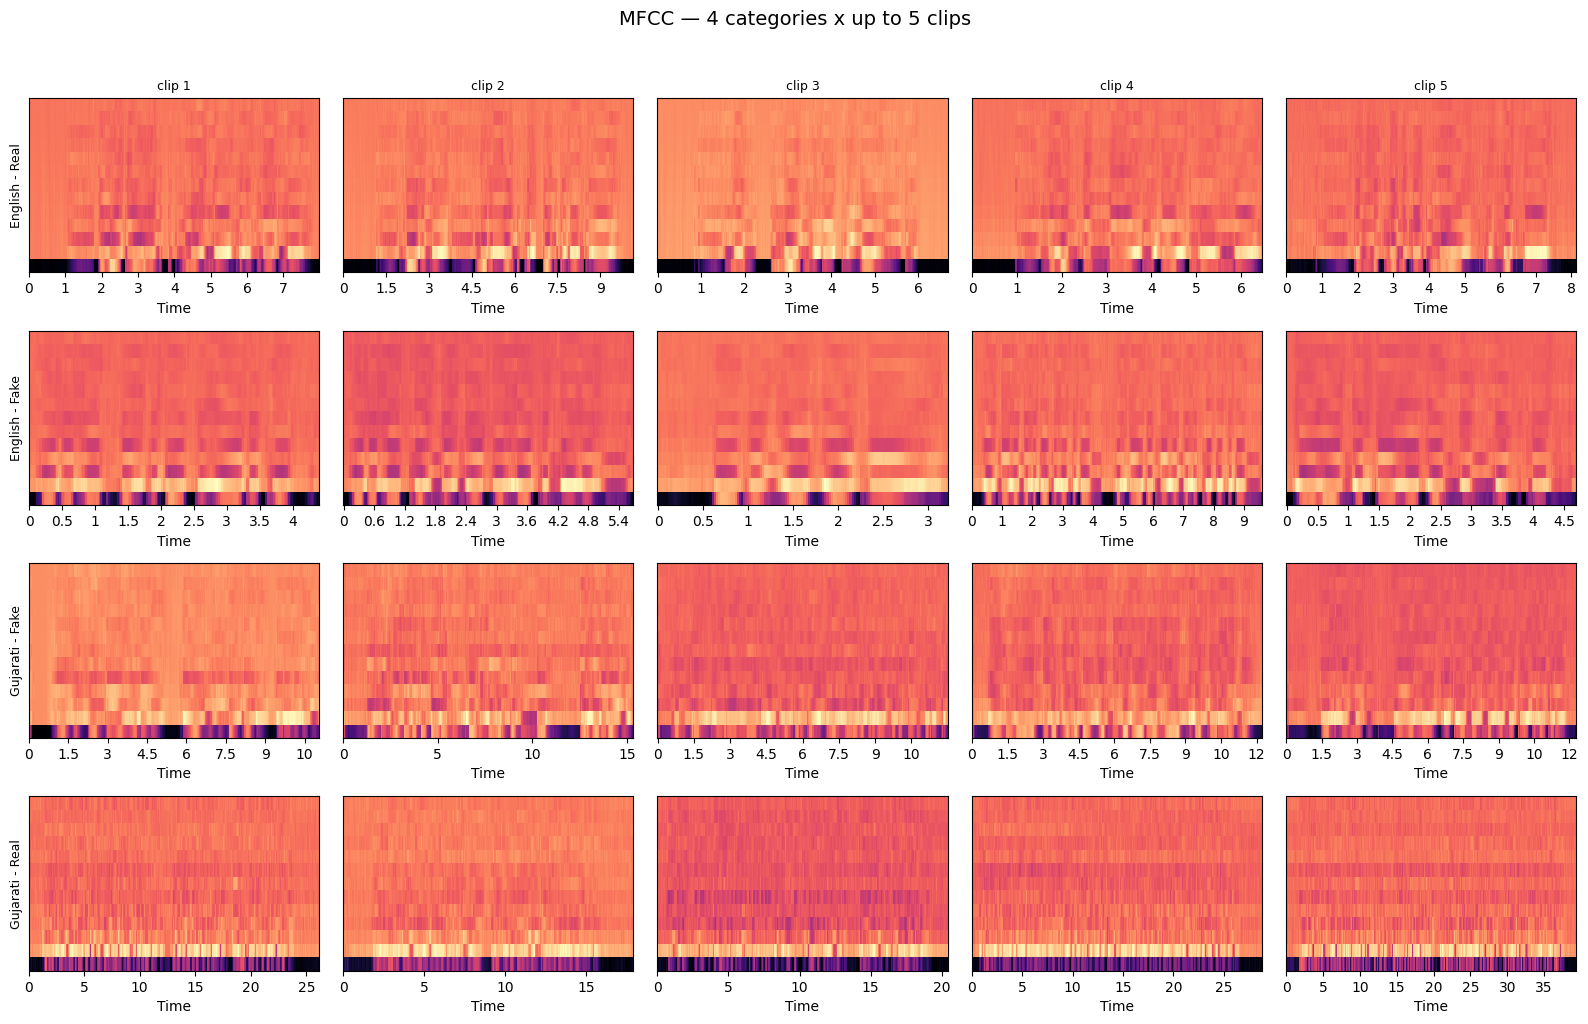

In [ ]:
plot_feature_grid("mfcc")

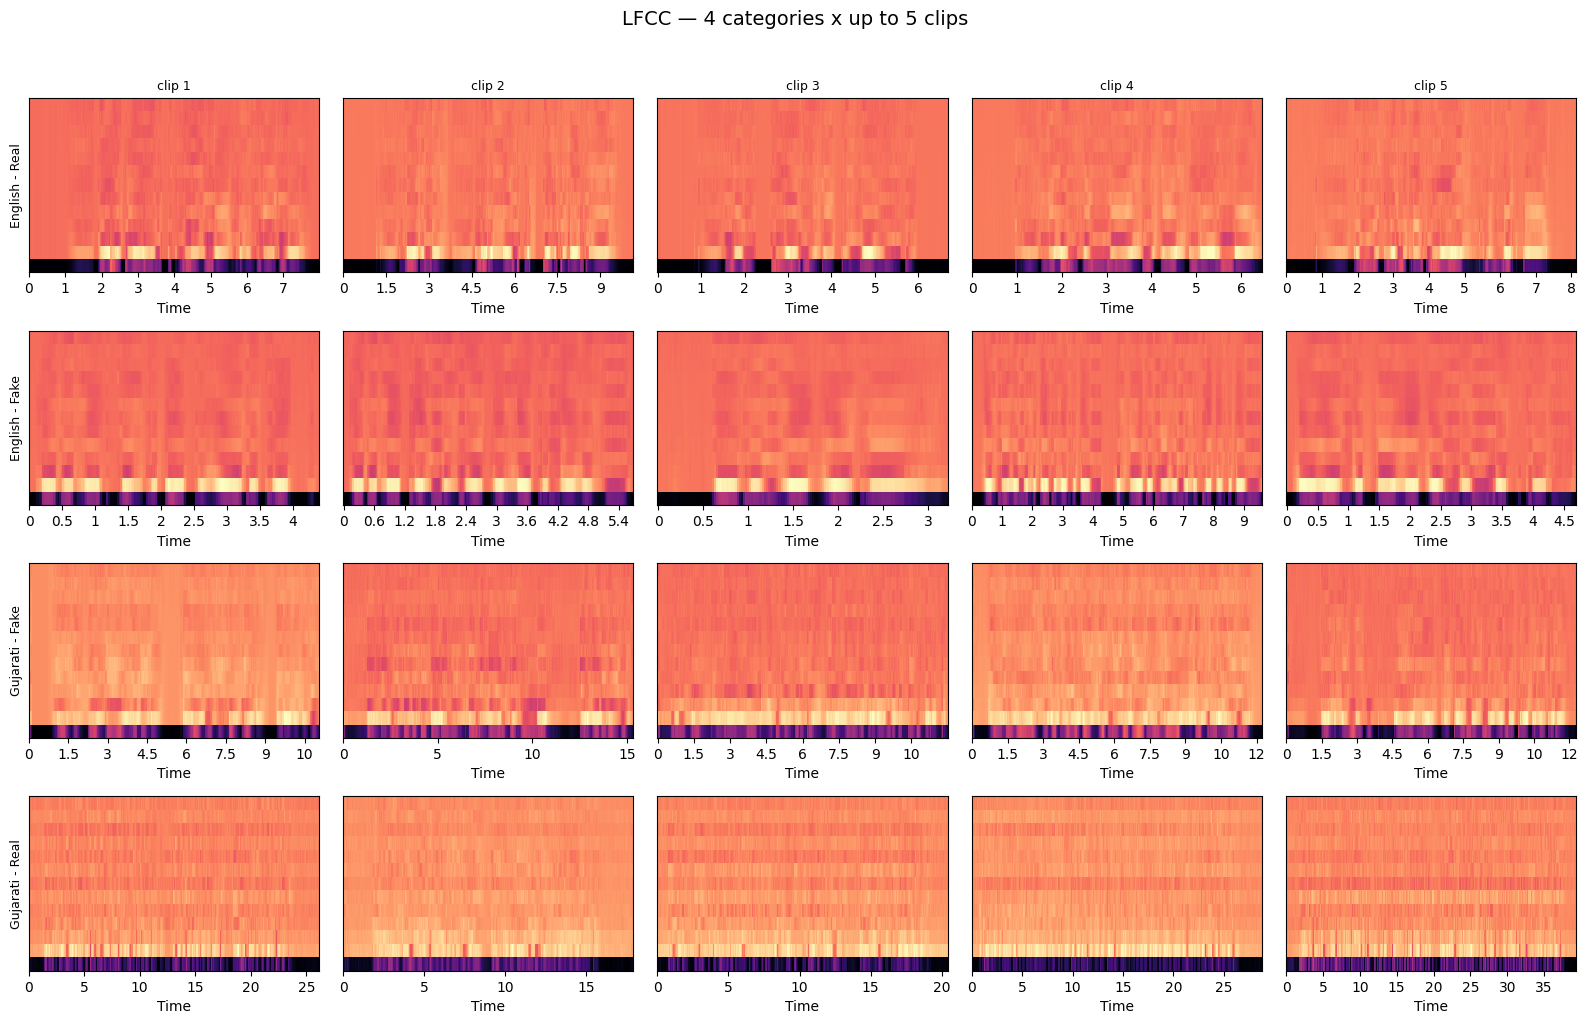

In [ ]:
plot_feature_grid("lfcc")

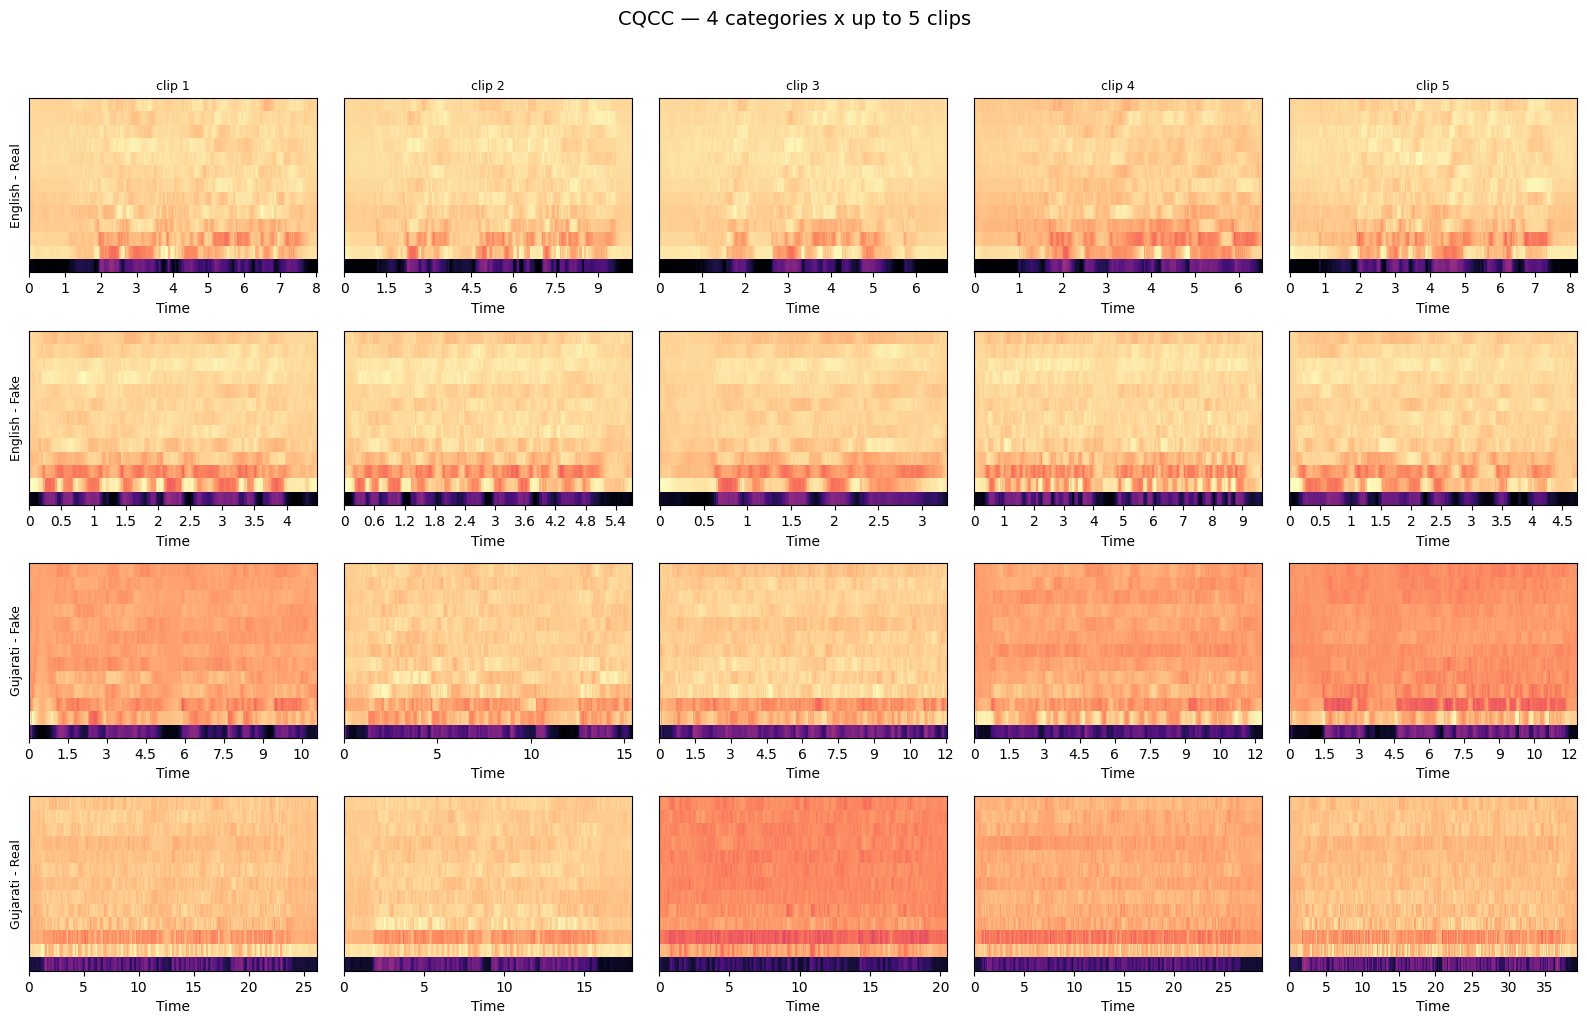

In [ ]:
plot_feature_grid("cqcc")